# Globe Temperature Prediction Using 2 Different Models

This notebook trains and evaluates Random Forest (RF) and Multiple Linear Regression (MLR) models to estimate black globe temperature (Tg) from conventional meteorological variables.

Two predictor configurations are compared: (1) four variables (T, RH, W, and SR) and (2) three variables (T, W, and SR), excluding relative humidity (RH).

Model performance is assessed using an 80/20 train-test split, five-fold GroupKFold cross-validation grouped by calendar day, and an external evaluation using January 2026 data. The impact of (Tg) estimation errors on WBGT is also evaluated while keeping air temperature and wet-bulb temperature estimates unchanged.

In [1]:
# Data manipulation
import pandas as pd
import numpy as np
from pathlib import Path
import joblib

# Machine learning models and validation
from sklearn.model_selection import train_test_split, GroupKFold
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression

# Model evaluation metrics
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Statistical analysis
import statsmodels.api as sm

# Visualization and regression analysis
import matplotlib.pyplot as plt
from scipy.stats import linregress

# Folders
base = Path.cwd().parent
data = base / "data"
results = base / "results"
results.mkdir(parents=True, exist_ok=True)

### Read the files for 2025 and 2026

The January–March 2025 dataset is used for model training and cross-validation. The January 2026 dataset is reserved for independent model evaluation.

In [2]:
ds_JFM_25 = pd.read_csv(data / "JFM_2025.csv")
ds_JAN_26 = pd.read_csv(data / "JAN_2026.csv")

# Convert timestamps to datetime
ds_JFM_25['time'] = pd.to_datetime(ds_JFM_25['time'])
ds_JAN_26['time'] = pd.to_datetime(ds_JAN_26['time'])

print("2025:", ds_JFM_25.shape)
print("2026:", ds_JAN_26.shape)

display(ds_JFM_25.tail(3))
display(ds_JAN_26.tail(3))

2025: (4820, 6)
2026: (424, 6)


,time,Tg,T,RH,W,SR
4817,2025-03-31 15:50:00,28.22,26.7,73,1.8,130
4818,2025-03-31 15:55:00,28.38,26.4,74,1.8,140
4819,2025-03-31 16:00:00,28.50,26.3,74,1.8,135


,time,Tg,T,RH,W,SR
421,2026-01-26 14:40:00,40.02,29.62,50.60,3.142,738.3911
422,2026-01-26 14:45:00,39.68,29.69,50.07,2.408,702.8136
423,2026-01-26 14:50:00,39.30,29.69,50.01,2.482,717.3292


### Data preparation

Two predictor configurations are considered:

- Four variables: T, RH, W, and SR.
- Three variables: T, W, and SR.

The same observations and train-test partitions are used for both configurations to ensure a consistent comparison. Records with missing values in any of the variables required for the comparison are excluded.

In [3]:
# Common dataset for model comparison
predictors_4 = ['T', 'RH', 'W', 'SR']
predictors_3 = ['T', 'W', 'SR']

df_2025 = ds_JFM_25[
    ['time', 'Tg'] + predictors_4
].dropna().copy()

y = df_2025['Tg'].astype(float)

X4 = df_2025[predictors_4].astype(float)
X3 = df_2025[predictors_3].astype(float)

# Common 80/20 train-test split
train_idx, test_idx = train_test_split(
    np.arange(len(df_2025)),
    test_size=0.20,
    random_state=90
)

X_train_4 = X4.iloc[train_idx]
X_test_4 = X4.iloc[test_idx]

X_train_3 = X3.iloc[train_idx]
X_test_3 = X3.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print(f"Observations: {len(df_2025)}")
print(f"Training observations: {len(train_idx)}")
print(f"Testing observations: {len(test_idx)}")

Observations: 4820
Training observations: 3856
Testing observations: 964


### Train the Random Forest (RF) models

Two RF configurations are trained using the same training observations and hyperparameters. The first uses four meteorological predictors, whereas the second excludes RH.

In [4]:
# Random Forest with four predictors
rf_model_4 = RandomForestRegressor(
    n_estimators=500,
    min_samples_leaf=5,
    random_state=90,
    n_jobs=-1
)

rf_model_4.fit(X_train_4, y_train)
y_pred_rf_4 = rf_model_4.predict(X_test_4)

# Random Forest with three predictors
rf_model_3 = RandomForestRegressor(
    n_estimators=500,
    min_samples_leaf=5,
    random_state=90,
    n_jobs=-1
)

rf_model_3.fit(X_train_3, y_train)
y_pred_rf_3 = rf_model_3.predict(X_test_3)

# Save models
joblib.dump(rf_model_4, results / "RF_4vars_JFM_2025.pkl")
joblib.dump(rf_model_3, results / "RF_3vars_JFM_2025.pkl")

# Performance metrics
rf_split_predictions = {
    'RF (4 variables)': y_pred_rf_4,
    'RF (3 variables)': y_pred_rf_3
}

for name, prediction in rf_split_predictions.items():
    print(f"\n{name}")
    print(f"R²   = {r2_score(y_test, prediction):.3f}")
    print(f"RMSE = {np.sqrt(mean_squared_error(y_test, prediction)):.3f} °C")
    print(f"MAE  = {mean_absolute_error(y_test, prediction):.3f} °C")

# Feature importance
print("\nRF feature importance")

print("\nFour predictors:")
display(pd.DataFrame({
    'Variable': predictors_4,
    'Importance (%)': rf_model_4.feature_importances_ * 100
}).round(2))

print("\nThree predictors:")
display(pd.DataFrame({
    'Variable': predictors_3,
    'Importance (%)': rf_model_3.feature_importances_ * 100
}).round(2))


RF (4 variables)
R²   = 0.895
RMSE = 1.019 °C
MAE  = 0.776 °C

RF (3 variables)
R²   = 0.890
RMSE = 1.044 °C
MAE  = 0.805 °C

RF feature importance

Four predictors:


,Variable,Importance (%)
0,T,15.02
1,RH,2.07
2,W,4.47
3,SR,78.44



Three predictors:


,Variable,Importance (%)
0,T,15.69
1,W,4.67
2,SR,79.63


### Random Forest with five-fold GroupKFold cross-validation

GroupKFold cross-validation is performed by grouping observations according to their calendar day. Thus, all observations recorded on the same day are assigned to either the training or testing subset within each fold.

The same folds are used for the four- and three-predictor configurations.

In [5]:
# Groups based on calendar day
groups = df_2025['time'].dt.normalize()

gkf = GroupKFold(n_splits=5)

rf_gkf_results = {}
rf_gkf_predictions = {}

for name, X in [
    ('RF (4 variables)', X4),
    ('RF (3 variables)', X3)
]:
    fold_metrics = []
    y_true_all = []
    y_pred_all = []

    for train_idx_gkf, test_idx_gkf in gkf.split(X, y, groups=groups):

        rf_gkf_model = RandomForestRegressor(
            n_estimators=500,
            min_samples_leaf=5,
            random_state=90,
            n_jobs=-1
        )

        rf_gkf_model.fit(
            X.iloc[train_idx_gkf],
            y.iloc[train_idx_gkf]
        )

        y_pred_gkf = rf_gkf_model.predict(
            X.iloc[test_idx_gkf]
        )

        y_test_gkf = y.iloc[test_idx_gkf]

        fold_metrics.append({
            'R2': r2_score(y_test_gkf, y_pred_gkf),
            'RMSE': np.sqrt(mean_squared_error(y_test_gkf, y_pred_gkf)),
            'MAE': mean_absolute_error(y_test_gkf, y_pred_gkf)
        })

        y_true_all.extend(y_test_gkf.values)
        y_pred_all.extend(y_pred_gkf)

    fold_df = pd.DataFrame(fold_metrics)

    rf_gkf_results[name] = {
        'R2_mean': fold_df['R2'].mean(),
        'R2_std': fold_df['R2'].std(ddof=0),
        'RMSE_mean': fold_df['RMSE'].mean(),
        'RMSE_std': fold_df['RMSE'].std(ddof=0),
        'MAE_mean': fold_df['MAE'].mean(),
        'MAE_std': fold_df['MAE'].std(ddof=0),
        'RMSE_pooled': np.sqrt(mean_squared_error(y_true_all, y_pred_all)),
        'MAE_pooled': mean_absolute_error(y_true_all, y_pred_all)
    }

    rf_gkf_predictions[name] = (
        np.array(y_true_all),
        np.array(y_pred_all)
    )

display(pd.DataFrame(rf_gkf_results).T.round(3))

,R2_mean,R2_std,RMSE_mean,RMSE_std,MAE_mean,MAE_std,RMSE_pooled,MAE_pooled
RF (4 variables),0.832,0.040,1.219,0.102,0.950,0.070,1.223,0.950
RF (3 variables),0.833,0.039,1.214,0.088,0.943,0.053,1.217,0.943


### WBGT estimation using RF predictions

Wet-bulb temperature is estimated using the empirical equation proposed by Stull (2011). RH is retained for this calculation in both predictor configurations because its exclusion applies only to the estimation of Tg.

The comparison isolates the contribution of Tg estimation errors to WBGT, while keeping the other terms identical.

In [6]:
# Wet-bulb temperature estimation (Stull, 2011)
def calc_Tw_stull(T, RH):
    return (
        T * np.arctan(0.151977 * np.sqrt(RH + 8.313659))
        + np.arctan(T + RH)
        - np.arctan(RH - 1.676331)
        + 0.00391838 * (RH ** 1.5) * np.arctan(0.023101 * RH)
        - 4.686035
    )

T_test = df_2025.iloc[test_idx]['T']
RH_test = df_2025.iloc[test_idx]['RH']
Tw_test = calc_Tw_stull(T_test, RH_test)

# Observed WBGT
WBGT_obs = (
    0.7 * Tw_test
    + 0.2 * y_test
    + 0.1 * T_test
)

# Estimated WBGT using RF predictions
WBGT_pred_rf_4 = (
    0.7 * Tw_test
    + 0.2 * y_pred_rf_4
    + 0.1 * T_test
)

WBGT_pred_rf_3 = (
    0.7 * Tw_test
    + 0.2 * y_pred_rf_3
    + 0.1 * T_test
)

for name, prediction in [
    ('RF (4 variables)', WBGT_pred_rf_4),
    ('RF (3 variables)', WBGT_pred_rf_3)
]:
    print(f"\n{name} — WBGT")
    print(f"R²   = {r2_score(WBGT_obs, prediction):.3f}")
    print(f"RMSE = {np.sqrt(mean_squared_error(WBGT_obs, prediction)):.3f} °C")
    print(f"MAE  = {mean_absolute_error(WBGT_obs, prediction):.3f} °C")


RF (4 variables) — WBGT
R²   = 0.974
RMSE = 0.204 °C
MAE  = 0.155 °C

RF (3 variables) — WBGT
R²   = 0.972
RMSE = 0.209 °C
MAE  = 0.161 °C


### Observed vs. estimated Tg using RF

The observed and estimated Tg values from the three-predictor RF model are compared against the 1:1 line.

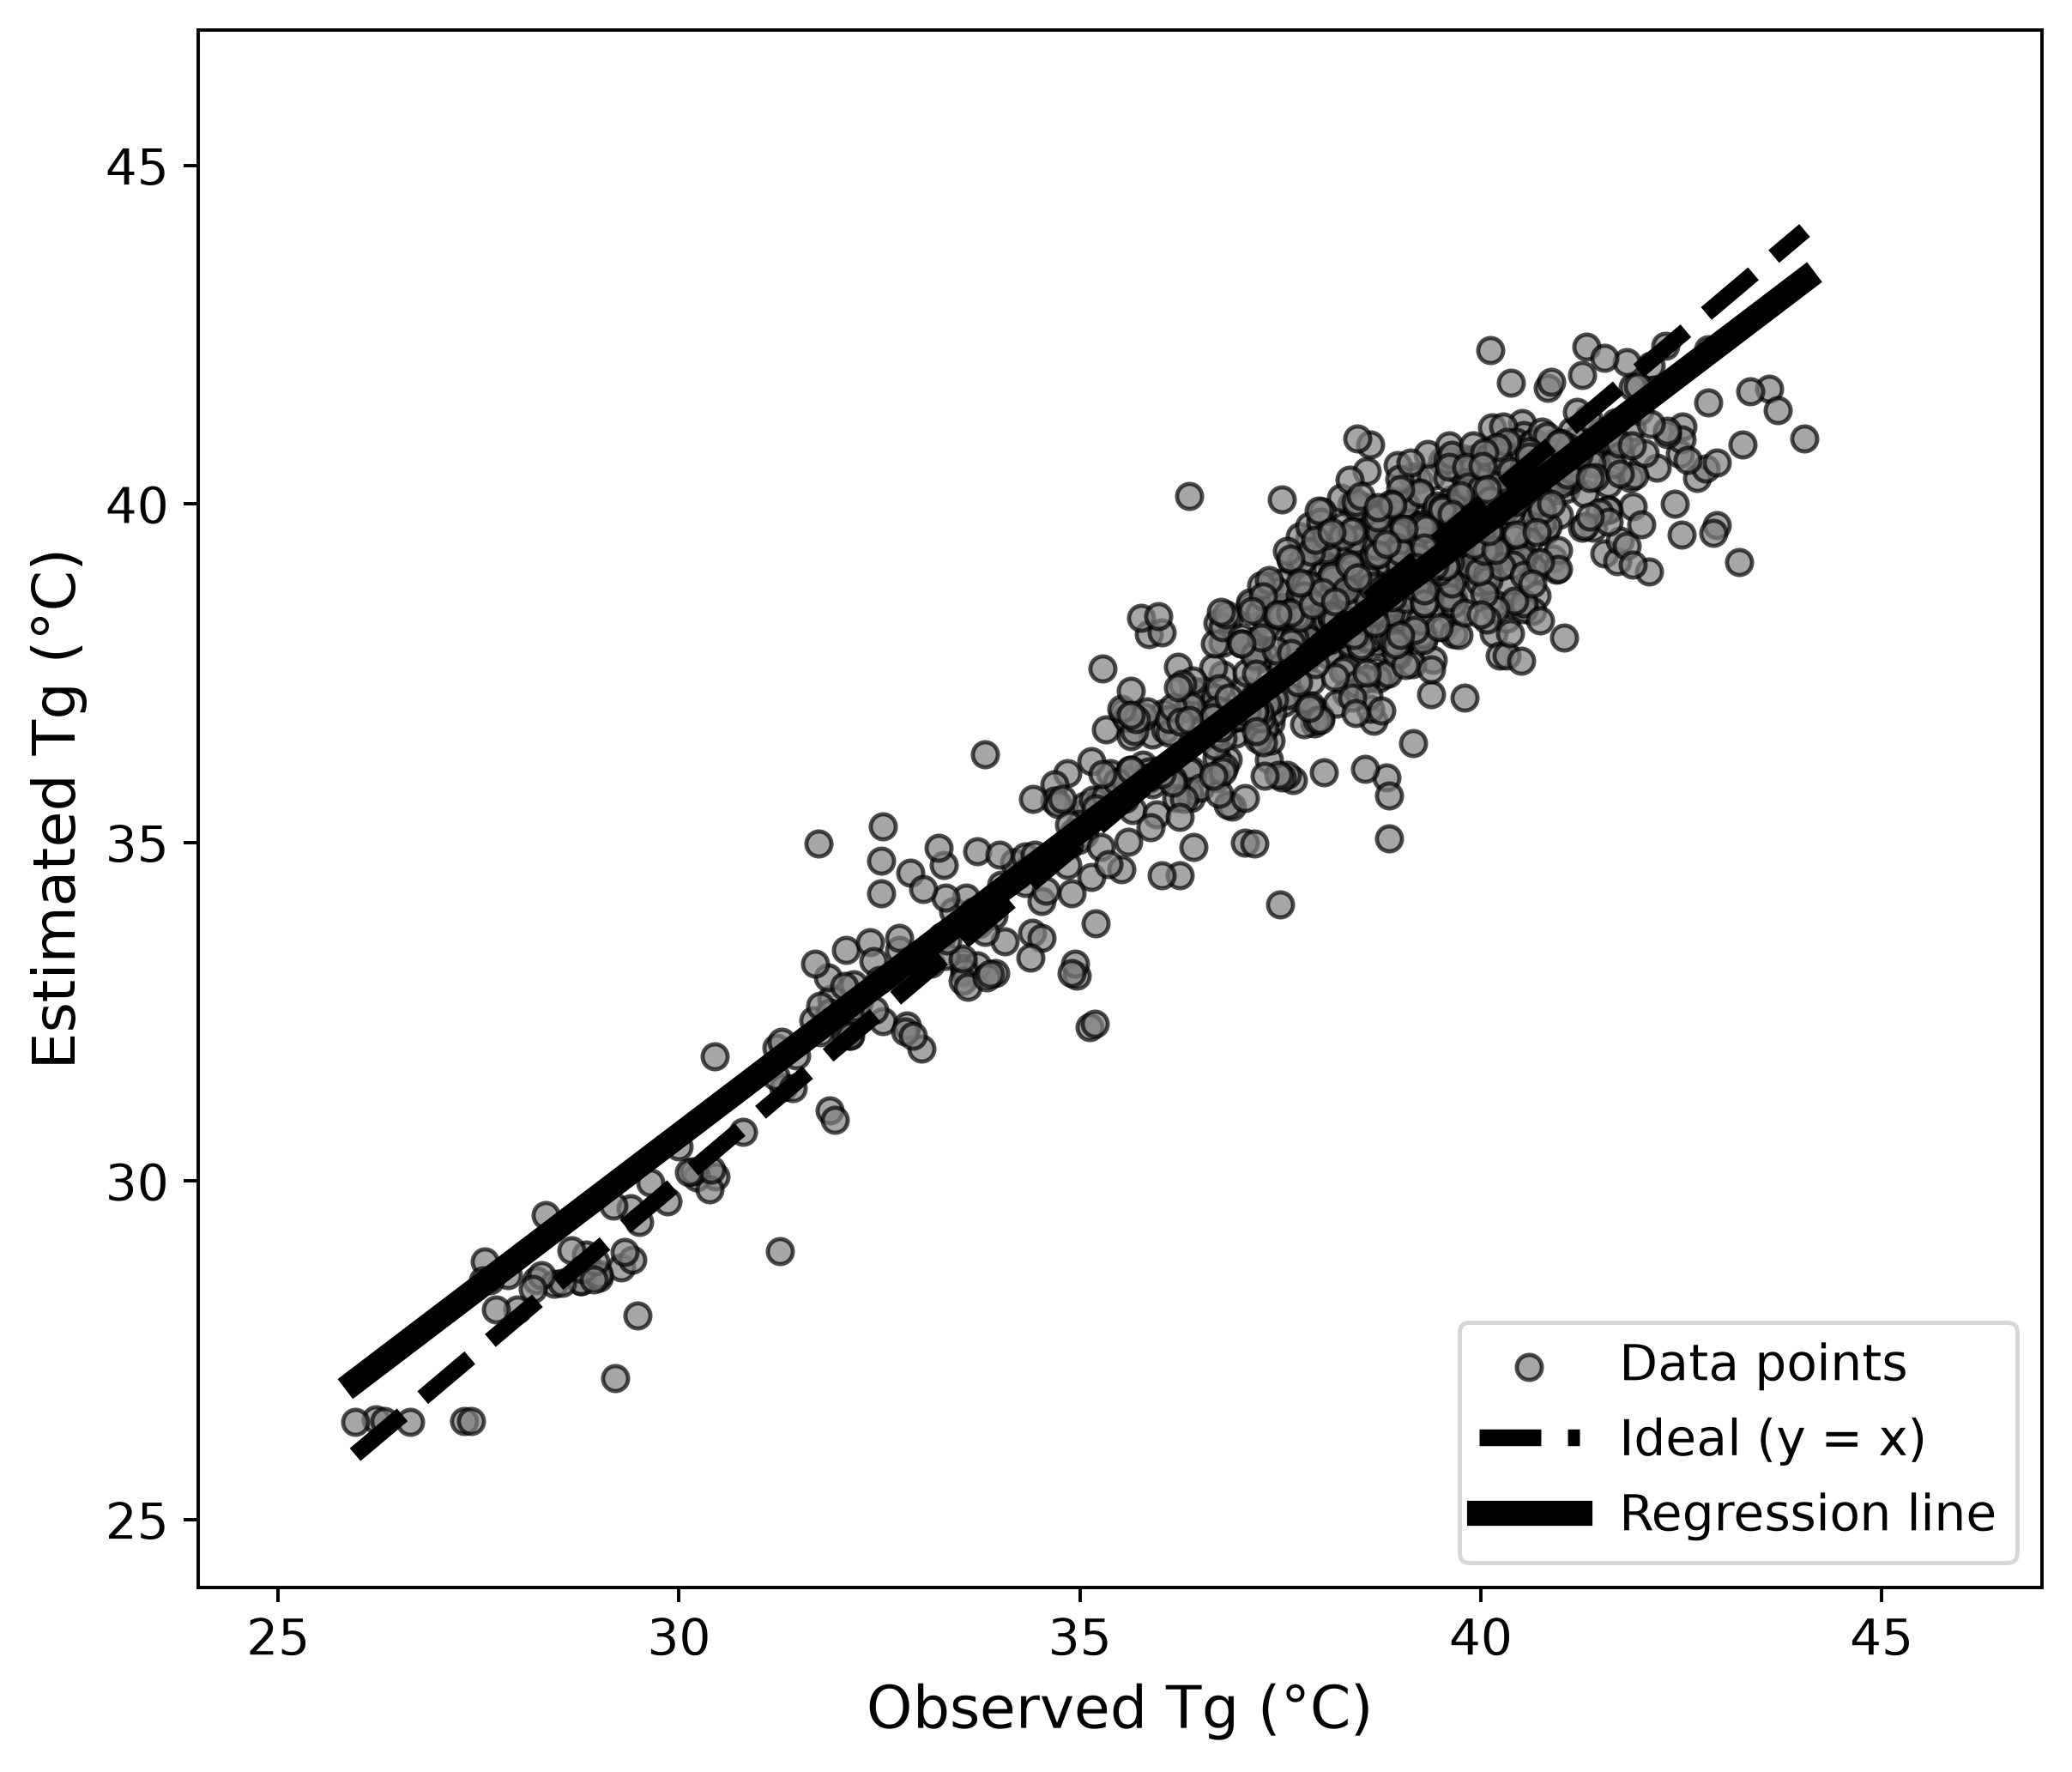

In [7]:
slope_rf_3, intercept_rf_3, _, _, _ = linregress(y_test, y_pred_rf_3)

plt.figure(figsize=(7, 6), dpi=350)

plt.scatter(
    y_test,
    y_pred_rf_3,
    alpha=0.7,
    color='gray',
    edgecolor='k',
    label="Data points"
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='black',
    linestyle='--',
    label='Ideal (y = x)',
    linewidth=4
)

x_vals = np.array([y_test.min(), y_test.max()])
y_vals = intercept_rf_3 + slope_rf_3 * x_vals

plt.plot(
    x_vals,
    y_vals,
    'k-',
    linewidth=6,
    label='Regression line'
)

plt.xlabel("Observed Tg (°C)", fontsize=14)
plt.ylabel("Estimated Tg (°C)", fontsize=14)
plt.xlim(24, 47)
plt.ylim(24, 47)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend(fontsize=12, loc='lower right')
plt.tight_layout()

plt.savefig(
    results / "RF_3vars_plot.png",
    dpi=500,
    bbox_inches="tight"
)

plt.show()

### Train the Multiple Linear Regression (MLR) models

Two MLR configurations are fitted using the same training observations: one with four predictors and another with three predictors, excluding RH. Their regression coefficients and predictive performance are compared.

In [8]:
# Multiple Linear Regression with four predictors
mlr_model_4 = LinearRegression()
mlr_model_4.fit(X_train_4, y_train)

y_pred_mlr_4 = mlr_model_4.predict(X_test_4)

# Multiple Linear Regression with three predictors
mlr_model_3 = LinearRegression()
mlr_model_3.fit(X_train_3, y_train)

y_pred_mlr_3 = mlr_model_3.predict(X_test_3)

# Save models
joblib.dump(mlr_model_4, results / "MLR_4vars_JFM_2025.pkl")
joblib.dump(mlr_model_3, results / "MLR_3vars_JFM_2025.pkl")

# Performance metrics
mlr_split_predictions = {
    'MLR (4 variables)': y_pred_mlr_4,
    'MLR (3 variables)': y_pred_mlr_3
}

for name, prediction in mlr_split_predictions.items():
    print(f"\n{name}")
    print(f"R²   = {r2_score(y_test, prediction):.3f}")
    print(f"RMSE = {np.sqrt(mean_squared_error(y_test, prediction)):.3f} °C")
    print(f"MAE  = {mean_absolute_error(y_test, prediction):.3f} °C")

# Regression equations
print("\nMLR equation — four predictors")
print(
    f"Tg = {mlr_model_4.intercept_:.6f} "
    f"+ {mlr_model_4.coef_[0]:.6f}*T "
    f"+ {mlr_model_4.coef_[1]:.6f}*RH "
    f"+ {mlr_model_4.coef_[2]:.6f}*W "
    f"+ {mlr_model_4.coef_[3]:.6f}*SR"
)

print("\nMLR equation — three predictors")
print(
    f"Tg = {mlr_model_3.intercept_:.6f} "
    f"+ {mlr_model_3.coef_[0]:.6f}*T "
    f"+ {mlr_model_3.coef_[1]:.6f}*W "
    f"+ {mlr_model_3.coef_[2]:.6f}*SR"
)


MLR (4 variables)
R²   = 0.793
RMSE = 1.430 °C
MAE  = 1.126 °C

MLR (3 variables)
R²   = 0.791
RMSE = 1.434 °C
MAE  = 1.128 °C

MLR equation — four predictors
Tg = 10.661409 + 0.822573*T + -0.014319*RH + -1.065556*W + 0.010735*SR

MLR equation — three predictors
Tg = 8.346869 + 0.866395*T + -1.029618*W + 0.010682*SR


### Multiple Linear Regression with five-fold GroupKFold cross-validation

The MLR configurations are evaluated using the same five-fold GroupKFold partitions as the RF models. Observations are grouped by calendar day to prevent measurements from the same day from being distributed between the training and testing subsets.

In [9]:
mlr_gkf_results = {}
mlr_gkf_predictions = {}

for name, X in [
    ('MLR (4 variables)', X4),
    ('MLR (3 variables)', X3)
]:
    fold_metrics = []
    y_true_all = []
    y_pred_all = []

    for train_idx_gkf, test_idx_gkf in gkf.split(X, y, groups=groups):

        mlr_gkf_model = LinearRegression()

        mlr_gkf_model.fit(
            X.iloc[train_idx_gkf],
            y.iloc[train_idx_gkf]
        )

        y_pred_gkf = mlr_gkf_model.predict(
            X.iloc[test_idx_gkf]
        )

        y_test_gkf = y.iloc[test_idx_gkf]

        fold_metrics.append({
            'R2': r2_score(y_test_gkf, y_pred_gkf),
            'RMSE': np.sqrt(mean_squared_error(y_test_gkf, y_pred_gkf)),
            'MAE': mean_absolute_error(y_test_gkf, y_pred_gkf)
        })

        y_true_all.extend(y_test_gkf.values)
        y_pred_all.extend(y_pred_gkf)

    fold_df = pd.DataFrame(fold_metrics)

    mlr_gkf_results[name] = {
        'R2_mean': fold_df['R2'].mean(),
        'R2_std': fold_df['R2'].std(ddof=0),
        'RMSE_mean': fold_df['RMSE'].mean(),
        'RMSE_std': fold_df['RMSE'].std(ddof=0),
        'MAE_mean': fold_df['MAE'].mean(),
        'MAE_std': fold_df['MAE'].std(ddof=0),
        'RMSE_pooled': np.sqrt(mean_squared_error(y_true_all, y_pred_all)),
        'MAE_pooled': mean_absolute_error(y_true_all, y_pred_all)
    }

    mlr_gkf_predictions[name] = (
        np.array(y_true_all),
        np.array(y_pred_all)
    )

display(pd.DataFrame(mlr_gkf_results).T.round(3))

,R2_mean,R2_std,RMSE_mean,RMSE_std,MAE_mean,MAE_std,RMSE_pooled,MAE_pooled
MLR (4 variables),0.767,0.018,1.467,0.222,1.146,0.132,1.482,1.145
MLR (3 variables),0.771,0.018,1.456,0.215,1.140,0.130,1.470,1.139


### WBGT estimation using MLR predictions

WBGT estimates are calculated using the predicted Tg values from both MLR configurations. The same wet-bulb temperature proxy and air temperature are used in the observed and estimated indices to isolate the contribution of Tg estimation errors.

In [10]:
# Estimated WBGT using MLR predictions
WBGT_pred_mlr_4 = (
    0.7 * Tw_test
    + 0.2 * y_pred_mlr_4
    + 0.1 * T_test
)

WBGT_pred_mlr_3 = (
    0.7 * Tw_test
    + 0.2 * y_pred_mlr_3
    + 0.1 * T_test
)

for name, prediction in [
    ('MLR (4 variables)', WBGT_pred_mlr_4),
    ('MLR (3 variables)', WBGT_pred_mlr_3)
]:
    print(f"\n{name} — WBGT")
    print(f"R²   = {r2_score(WBGT_obs, prediction):.3f}")
    print(f"RMSE = {np.sqrt(mean_squared_error(WBGT_obs, prediction)):.3f} °C")
    print(f"MAE  = {mean_absolute_error(WBGT_obs, prediction):.3f} °C")


MLR (4 variables) — WBGT
R²   = 0.948
RMSE = 0.286 °C
MAE  = 0.225 °C

MLR (3 variables) — WBGT
R²   = 0.948
RMSE = 0.287 °C
MAE  = 0.226 °C


### Observed vs. estimated Tg using MLR

The observed and estimated Tg values from the three-predictor MLR model are compared against the 1:1 line.

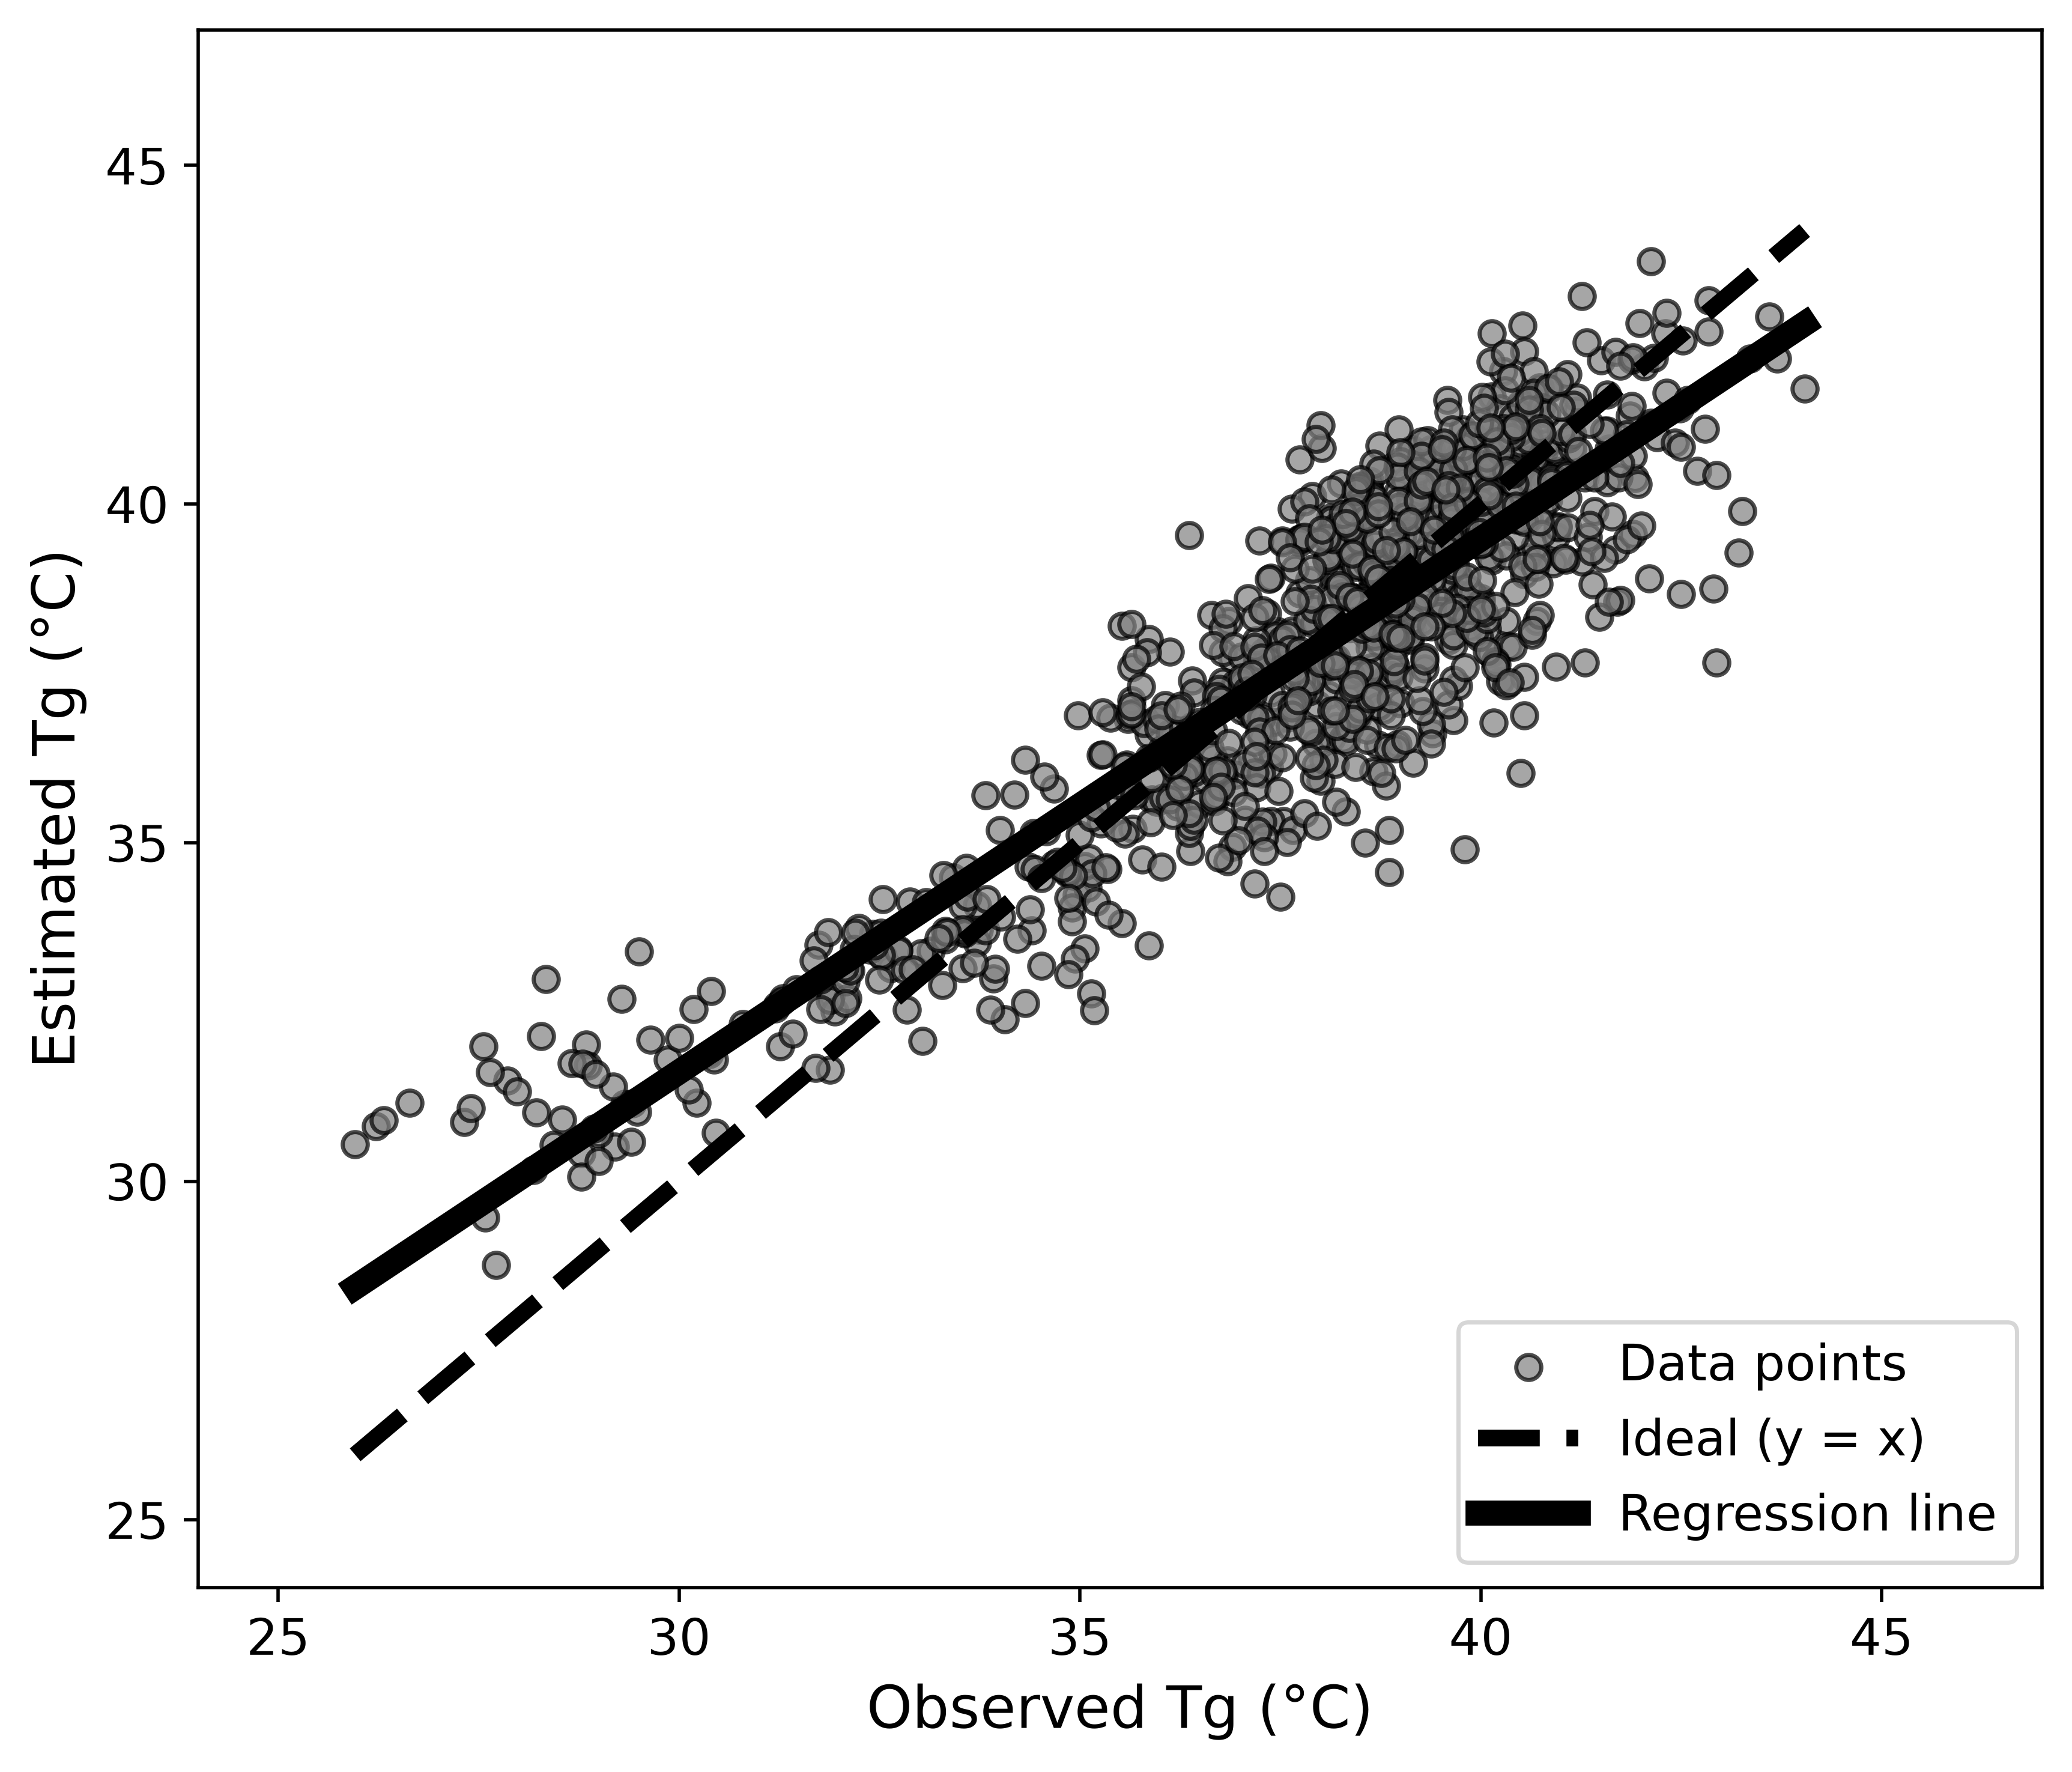

In [11]:
slope_mlr_3, intercept_mlr_3, _, _, _ = linregress(y_test, y_pred_mlr_3)

plt.figure(figsize=(7, 6), dpi=500)

plt.scatter(
    y_test,
    y_pred_mlr_3,
    alpha=0.7,
    color='gray',
    edgecolor='k',
    label="Data points"
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='black',
    linestyle='--',
    label='Ideal (y = x)',
    linewidth=4
)

x_vals = np.array([y_test.min(), y_test.max()])
y_vals = intercept_mlr_3 + slope_mlr_3 * x_vals

plt.plot(
    x_vals,
    y_vals,
    'k-',
    linewidth=6,
    label='Regression line'
)

plt.xlabel("Observed Tg (°C)", fontsize=14)
plt.ylabel("Estimated Tg (°C)", fontsize=14)
plt.xlim(24, 47)
plt.ylim(24, 47)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend(fontsize=12, loc='lower right')
plt.tight_layout()

plt.savefig(
    results / "MLR_3vars_plot.png",
    dpi=500,
    bbox_inches="tight"
)

plt.show()

### Independent evaluation using January 2026 data

The four models trained using the 2025 training subset are evaluated against the January 2026 observations. The same complete cases are used for all four configurations to ensure a consistent comparison.

In [12]:
# Common complete cases for the four configurations
df_2026 = ds_JAN_26[
    ['Tg', 'T', 'RH', 'W', 'SR']
].dropna().copy()

X_2026_4 = df_2026[predictors_4].astype(float)
X_2026_3 = df_2026[predictors_3].astype(float)
y_2026 = df_2026['Tg'].astype(float)

# Predictions
predictions_2026 = {
    'RF (4 variables)': rf_model_4.predict(X_2026_4),
    'RF (3 variables)': rf_model_3.predict(X_2026_3),
    'MLR (4 variables)': mlr_model_4.predict(X_2026_4),
    'MLR (3 variables)': mlr_model_3.predict(X_2026_3)
}

# External evaluation
external_results = {}

for name, prediction in predictions_2026.items():
    external_results[name] = {
        'R2': r2_score(y_2026, prediction),
        'RMSE': np.sqrt(mean_squared_error(y_2026, prediction)),
        'MAE': mean_absolute_error(y_2026, prediction)
    }

    print(f"\n{name} — January 2026")
    print(f"R²   = {external_results[name]['R2']:.3f}")
    print(f"RMSE = {external_results[name]['RMSE']:.3f} °C")
    print(f"MAE  = {external_results[name]['MAE']:.3f} °C")


RF (4 variables) — January 2026
R²   = 0.889
RMSE = 1.230 °C
MAE  = 0.905 °C

RF (3 variables) — January 2026
R²   = 0.892
RMSE = 1.215 °C
MAE  = 0.879 °C

MLR (4 variables) — January 2026
R²   = 0.790
RMSE = 1.693 °C
MAE  = 1.388 °C

MLR (3 variables) — January 2026
R²   = 0.808
RMSE = 1.619 °C
MAE  = 1.298 °C


### Statistical significance of MLR predictors

Ordinary least squares models with heteroskedasticity and autocorrelation consistent (HAC) standard errors are fitted for both predictor configurations. A maximum lag of 12 observations is used to account for short-term temporal autocorrelation in the five-minute measurements.

In [13]:
# VIF with four predictors (T, RH, W, SR)
X_vif_4 = sm.add_constant(ds_JFM_25[['T', 'RH', 'W', 'SR']].astype(float))
vif_4_df = pd.DataFrame({
    "Variable": X_vif_4.columns,
    "VIF": [variance_inflation_factor(X_vif_4.values, i) for i in range(X_vif_4.shape[1])]
})

# VIF with three predictors (T, W, SR)
X_vif_3 = sm.add_constant(ds_JFM_25[['T', 'W', 'SR']].astype(float))
vif_3_df = pd.DataFrame({
    "Variable": X_vif_3.columns,
    "VIF": [variance_inflation_factor(X_vif_3.values, i) for i in range(X_vif_3.shape[1])]
})

print("[VIF - Four predictors]")
print(vif_4_df.iloc[1:].to_string(index=False))

print("\n[VIF - Three predictors]")
print(vif_3_df.iloc[1:].to_string(index=False))


# OLS with HAC standard errors (four predictors)
X_ols_4 = sm.add_constant(ds_JFM_25[['T', 'RH', 'W', 'SR']].astype(float))
ols_hac_4 = sm.OLS(
    ds_JFM_25['Tg'].astype(float), X_ols_4
).fit(cov_type='HAC', cov_kwds={'maxlags': 12})

# OLS with HAC standard errors (three predictors)
X_ols_3 = sm.add_constant(ds_JFM_25[['T', 'W', 'SR']].astype(float))
ols_hac_3 = sm.OLS(
    ds_JFM_25['Tg'].astype(float), X_ols_3
).fit(cov_type='HAC', cov_kwds={'maxlags': 12})


print("\nOLS with HAC standard errors — four predictors")
display(pd.DataFrame({
    'Coefficient': ols_hac_4.params,
    't-value': ols_hac_4.tvalues,
    'p-value': ols_hac_4.pvalues
}).round(4))

print("\nOLS with HAC standard errors — three predictors")
display(pd.DataFrame({
    'Coefficient': ols_hac_3.params,
    't-value': ols_hac_3.tvalues,
    'p-value': ols_hac_3.pvalues
}).round(4))

[VIF - Four predictors]
Variable      VIF
       T 3.104604
      RH 3.263335
       W 1.515285
      SR 1.368224

[VIF - Three predictors]
Variable      VIF
       T 1.252575
       W 1.301140
      SR 1.319879

OLS with HAC standard errors — four predictors


,Coefficient,t-value,p-value
const,11.7581,3.9933,0.0001
T,0.7995,12.1943,0.0000
RH,-0.0204,-1.0840,0.2784
W,-1.0857,-10.6009,0.0000
SR,0.0108,30.9803,0.0000



OLS with HAC standard errors — three predictors


,Coefficient,t-value,p-value
const,8.4633,7.7577,0.0
T,0.8618,23.4299,0.0
W,-1.0334,-9.0274,0.0
SR,0.0107,33.4268,0.0


### Comparison of model performance

The performance of the four model configurations is summarized using the 80/20 train-test split, GroupKFold cross-validation, WBGT error metrics, and the independent January 2026 evaluation.

In [14]:
# Predictions from the 80/20 split
split_predictions = {
    'RF (4 variables)': y_pred_rf_4,
    'RF (3 variables)': y_pred_rf_3,
    'MLR (4 variables)': y_pred_mlr_4,
    'MLR (3 variables)': y_pred_mlr_3
}

# WBGT predictions from the 80/20 split
wbgt_predictions = {
    'RF (4 variables)': WBGT_pred_rf_4,
    'RF (3 variables)': WBGT_pred_rf_3,
    'MLR (4 variables)': WBGT_pred_mlr_4,
    'MLR (3 variables)': WBGT_pred_mlr_3
}

# Combine GroupKFold results
gkf_results = {
    **rf_gkf_results,
    **mlr_gkf_results
}

comparison_rows = []

for name in split_predictions:

    prediction = split_predictions[name]
    wbgt_prediction = wbgt_predictions[name]
    gkf_metrics = gkf_results[name]
    ext = external_results[name]

    comparison_rows.append({
        'Model': name,

        'Val_R2': r2_score(y_test, prediction),
        'Val_RMSE': np.sqrt(mean_squared_error(y_test, prediction)),
        'Val_MAE': mean_absolute_error(y_test, prediction),

        'GKF_R2_mean': gkf_metrics['R2_mean'],
        'GKF_R2_std': gkf_metrics['R2_std'],
        'GKF_RMSE_mean': gkf_metrics['RMSE_mean'],
        'GKF_RMSE_std': gkf_metrics['RMSE_std'],
        'GKF_MAE_mean': gkf_metrics['MAE_mean'],
        'GKF_MAE_std': gkf_metrics['MAE_std'],
        'GKF_RMSE_pooled': gkf_metrics['RMSE_pooled'],
        'GKF_MAE_pooled': gkf_metrics['MAE_pooled'],

        'WBGT_R2': r2_score(WBGT_obs, wbgt_prediction),
        'WBGT_RMSE': np.sqrt(mean_squared_error(WBGT_obs, wbgt_prediction)),
        'WBGT_MAE': mean_absolute_error(WBGT_obs, wbgt_prediction),

        'Ext26_R2': ext['R2'],
        'Ext26_RMSE': ext['RMSE'],
        'Ext26_MAE': ext['MAE']
    })

comparison_df = pd.DataFrame(comparison_rows).set_index('Model')

# Round numerical values
comparison_df = comparison_df.round(3)

# Save results
comparison_df.to_csv(
    results / "model_comparison_3vs4_variables.csv"
)

display(comparison_df)

,Val_R2,Val_RMSE,Val_MAE,GKF_R2_mean,GKF_R2_std,GKF_RMSE_mean,GKF_RMSE_std,GKF_MAE_mean,GKF_MAE_std,GKF_RMSE_pooled,GKF_MAE_pooled,WBGT_R2,WBGT_RMSE,WBGT_MAE,Ext26_R2,Ext26_RMSE,Ext26_MAE
Model,,,,,,,,,,,,,,,,,
RF (4 variables),0.895,1.019,0.776,0.832,0.040,1.219,0.102,0.950,0.070,1.223,0.950,0.974,0.204,0.155,0.889,1.230,0.905
RF (3 variables),0.890,1.044,0.805,0.833,0.039,1.214,0.088,0.943,0.053,1.217,0.943,0.972,0.209,0.161,0.892,1.215,0.879
MLR (4 variables),0.793,1.430,1.126,0.767,0.018,1.467,0.222,1.146,0.132,1.482,1.145,0.948,0.286,0.225,0.790,1.693,1.388
MLR (3 variables),0.791,1.434,1.128,0.771,0.018,1.456,0.215,1.140,0.130,1.470,1.139,0.948,0.287,0.226,0.808,1.619,1.298
